In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.quinex_visualisation import QuinexVisualisation

In [2]:
visualisation = QuinexVisualisation()

### **Import Results**

### **Efficiency**

In [3]:
df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
efficiency = df[df["property_mapping"] == "Efficiency"]
print(efficiency["unit_normalized"].value_counts())
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                                                                                                                                                                                               18158
[{'exponent': None, 'text': None, 'unit_uri': 'http://qudt.org/vocab/unit/UNITLESS', 'year': None}]                                                                                                                                                                                             2496
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                                                                                                                                                                                            76
[{'exponent': 1.0, 'text': 'W/m2', 'unit_uri': 'http://qudt.org/vocab/unit/W-PER-M2', 'year': None}]     

unit_normalized
[{'exponent': 1.0, 'text': '%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]             18158
[{'exponent': 1.0, 'text': 'percent', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]          76
[{'exponent': 1.0, 'text': '.%', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                2
[{'exponent': 1.0, 'text': '%*', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]                1
[{'exponent': 1.0, 'text': 'percentage', 'unit_uri': 'http://qudt.org/vocab/unit/PERCENT', 'year': None}]        1
Name: count, dtype: int64

In [4]:
efficiency = visualisation.convert_spatial(efficiency, spatial_col="spatial_scope")
print(efficiency["entity_mapping"].value_counts())
efficiency = efficiency[efficiency["entity_mapping"] == "PV"]

entity_mapping
PV                             839
Bioenergy                       93
Wind                            68
Hydrogen                        59
Coal                            57
Geothermal                      54
Electrolyzer                    45
Natural Gas                     34
Battery                         26
Hybrid Energy System            21
Hydropower                      15
CCS                              9
Lithium-Ion Battery              9
Lead Acid Battery                8
Nuclear                          7
Offshore Wind                    4
Green Hydrogen                   4
Onshore Wind                     3
Liquefied Natural Gas (LNG)      2
DACCS                            1
Name: count, dtype: int64


#### **LCOE**

In [ ]:
cost_lcoe = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe2024.xlsx")
cost_lcoe = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['PV'])]

In [7]:
cost_lcoe = visualisation.convert_spatial(cost_lcoe, spatial_col="spatial_scope")
print(cost_lcoe["entity_base_mapping"].value_counts())

entity_base_mapping
PV    713
Name: count, dtype: int64


In [8]:
cost_lcoe = cost_lcoe[cost_lcoe["value_converted"] < 0.51]
len(cost_lcoe)

616

### **Cap Factor**

In [8]:
# df = pd.read_parquet("../data/visualisation_files/df_technologies.parquet")
# cap_factor_raw = df[df["property_mapping"] == "Capacity Factor"]
# percent = cap_factor_raw[
#     cap_factor_raw['unit_normalized'].apply(
#         lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
#     )
# ]

# unitless = cap_factor_raw[
#     cap_factor_raw['unit_normalized'].apply(
#         lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/UNITLESS'
#     )
# ]

# # nur Werte zwischen 0 und 1 behalten
# unitless = unitless[unitless['value_normalized'].between(0, 1)]

# # auf Prozent skalieren
# unitless['value_normalized'] = unitless['value_normalized'] * 100

# # zusammenführen
# cap_factor = pd.concat([percent, unitless], ignore_index=True)
# cap_factor["unit_normalized"].value_counts()

In [9]:
# cap_factor['entity_mapping'] = cap_factor['entity_mapping'].replace({
#     'Onshore Wind': 'Wind'
# })
# cap_factor = cap_factor[cap_factor["entity_mapping"].isin(["Wind"])]

In [10]:
# cap_factor = visualisation.convert_spatial(cap_factor, spatial_col="spatial_scope_refined")
# print(cap_factor["entity_mapping"].value_counts())

In [11]:
# cap_factor = cap_factor[(cap_factor["value_normalized"] > 10) & (cap_factor["value_normalized"] < 60)]
# len(cap_factor)

### **Visualize Results**

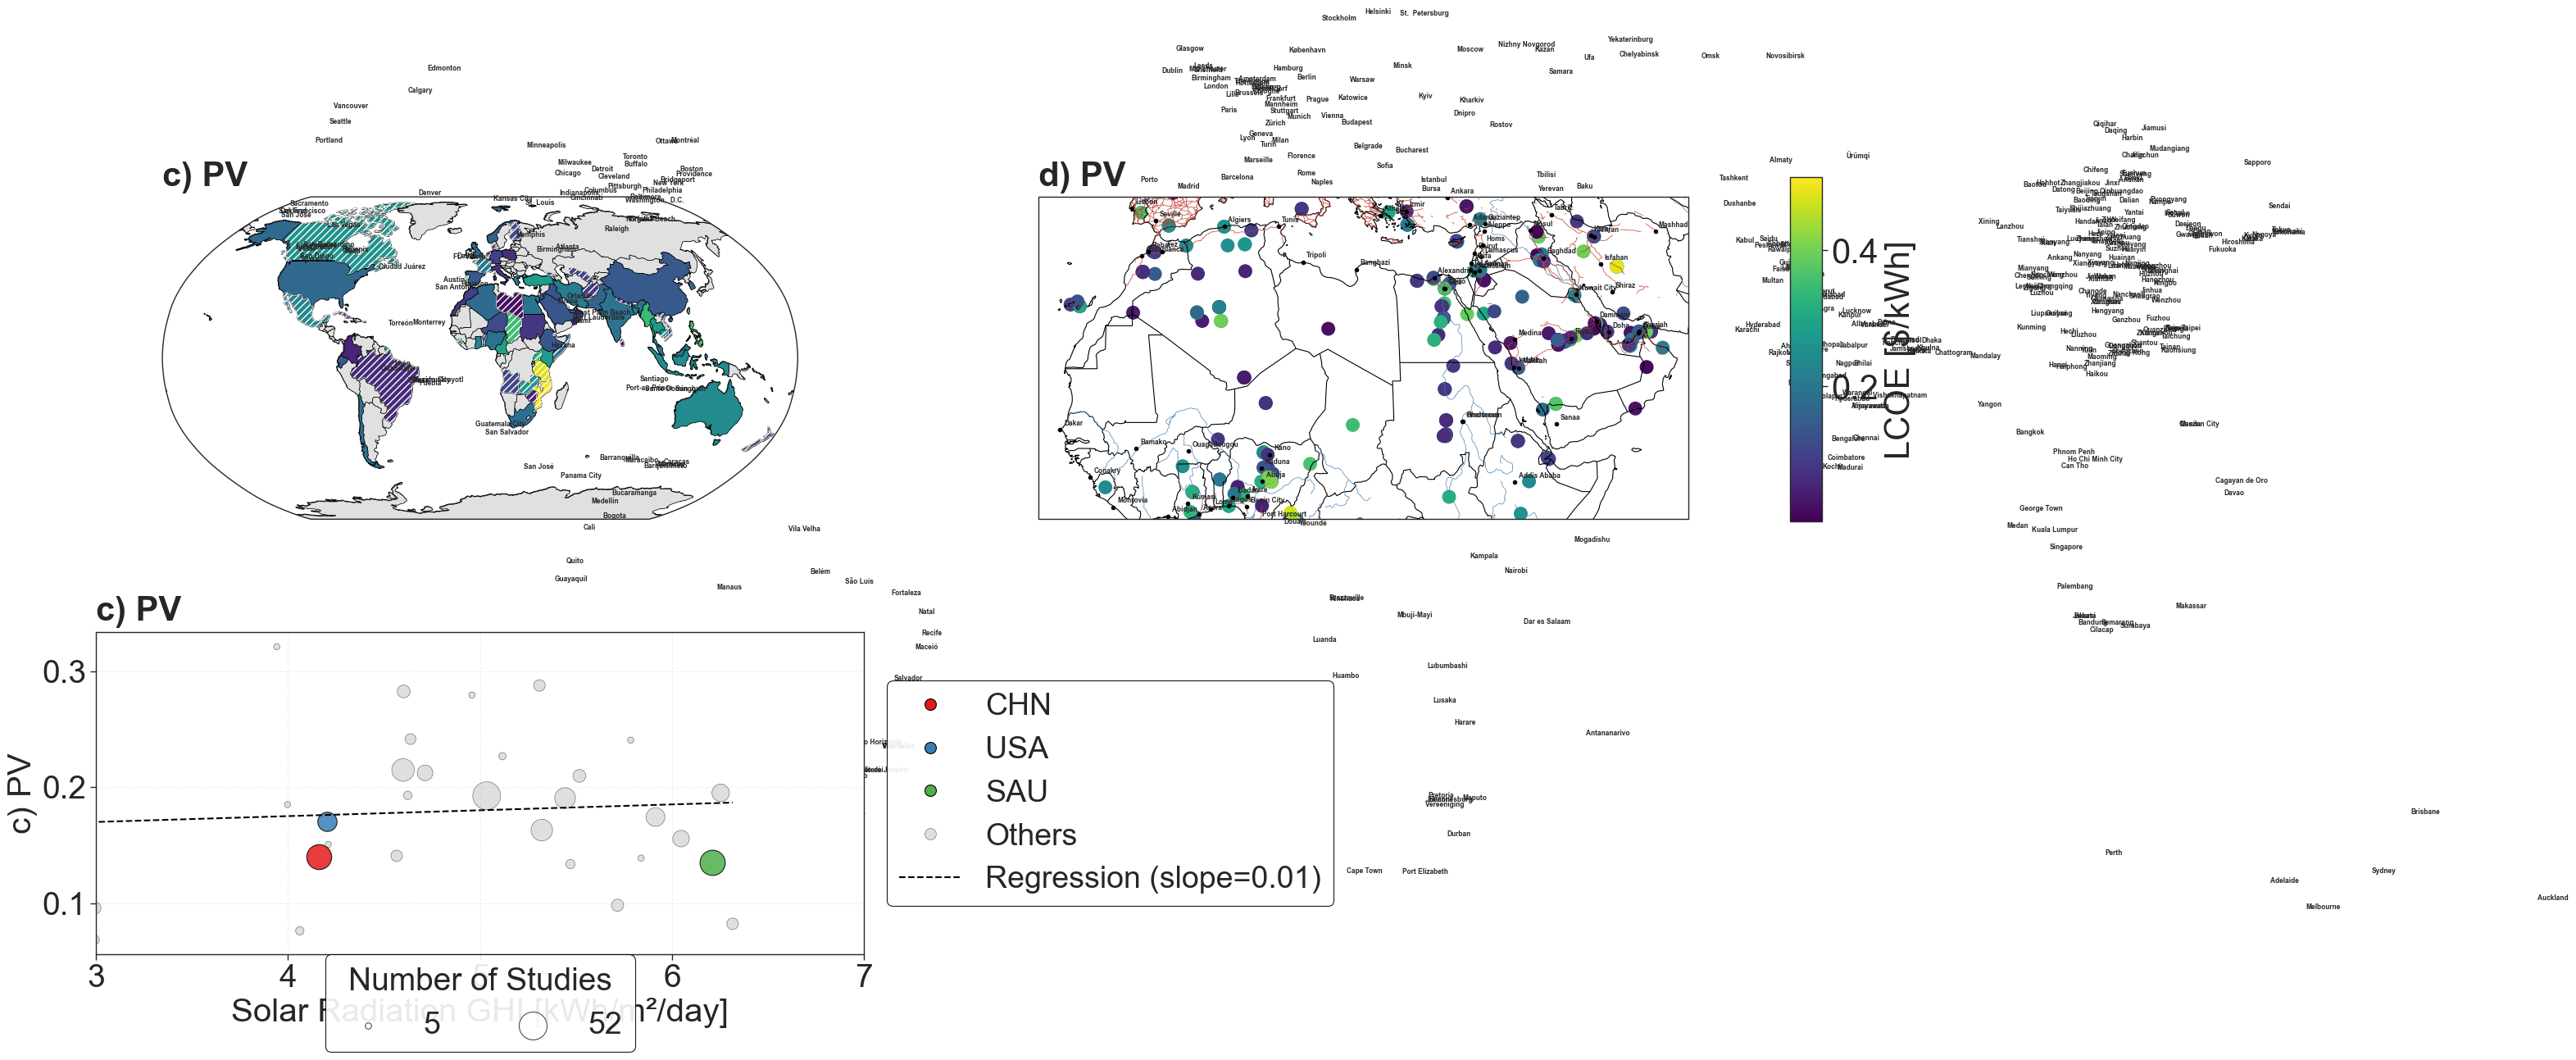

In [21]:
datasets = [
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'choropleth',
    'min_datapoints': 3,
    },
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'd) PV',
    'plot_mode': 'points',
    'spatial_extent': [-20, 60, 5, 40],
    'show_cities': 500,
    'show_rivers': True,
    'show_roads': "secondary",
    },
    {
    'df': cost_lcoe[cost_lcoe["value_converted"] < 0.85],
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'size',
    'ghi_data_path': "../data/visualisation_files/country_GHI_mean.xlsx",
    'highlight_countries': ['CHN', 'USA', 'SAU', 'MOZ', 'CAN'],
    'x_range': [3,7],
    'min_datapoints': 5,
    'show_regression': True,
    },
]

fig, data_tables = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="LCOE [$/kWh]",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=150,
    font_size=30,
)

#fig.savefig("../data/figures/results/spatial/lcoe_pv.pdf", bbox_inches='tight')

In [13]:
data_tables

{'c) PV':       country  avg_value  n_datapoints       ghi  bubble_size
 0         ARE   0.155682            20  6.047002   211.914894
 1         AUS   0.240515             5  5.784267    30.000000
 2         BGD   0.214817            35  4.599339   393.829787
 3         CHN   0.139722            42  4.159152   478.723404
 4         CMR   0.287702            11  5.309380   102.765957
 5       Chile   0.192940             7  4.623774    54.255319
 6         DEU   0.095833            12  2.994546   114.893617
 7         DZA   0.174286            25  5.913517   272.553191
 8         EGY   0.195143            22  6.253116   236.170213
 9         ESP   0.140852            11  4.565922   102.765957
 10        ETH   0.138844             5  5.839061    30.000000
 11    Ecuador   0.150670             5  4.209570    30.000000
 12        GBR   0.173652             8  2.583866    66.382979
 13        GHA   0.226762             6  5.116250    42.127660
 14  Hong Kong   0.321174             5  3.941

In [14]:
# Display scatter data (avg_value, n_datapoints, ghi per country)
for title, df_table in data_tables.items():
    print(f"\n--- {title} ---")
    display(df_table.sort_values("n_datapoints", ascending=False).head(20))


--- c) PV ---


,country,avg_value,n_datapoints,ghi,bubble_size
16,IND,0.192654,52,5.034712,600.000000
27,SAU,0.135269,43,6.207105,490.851064
3,CHN,0.139722,42,4.159152,478.723404
2,BGD,0.214817,35,4.599339,393.829787
25,PAK,0.163021,32,5.321666,357.446809
23,NGA,0.190612,30,5.442919,333.191489
31,USA,0.170432,26,4.202620,284.680851
7,DZA,0.174286,25,5.913517,272.553191
8,EGY,0.195143,22,6.253116,236.170213
0,ARE,0.155682,20,6.047002,211.914894


In [15]:
df_table[df_table["country"] == "TZA"]

,country,avg_value,n_datapoints,ghi,bubble_size


### **Investigate Results**

In [16]:
df = pd.read_excel("../data/visualisation_files/country_GHI_mean.xlsx")

In [17]:
df[df["Country"] == "Mali"]

,Country,GHI_mean
97,Mali,6.013666
